In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob

#sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

plt.rcParams["figure.figsize"] = [6,6]

/tmp/ipykernel_1646353/805219698.py:14: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')


All the fixes needed before running pyscenic 

In [2]:
# needed before from pyscenic.transform import df2regulons - not needed after the monkey-patch
# pip install "numpy<1.24" --upgrade --force-reinstall

In [3]:
# monkey-patch to resolve the pyscenic problem with numpy AttributeError
if not hasattr(np, "object"): np.object = object
if not hasattr(np, "bool"):   np.bool   = bool
if not hasattr(np, "int"):    np.int    = int
if not hasattr(np, "float"):  np.float  = float

/tmp/ipykernel_1646353/1380273315.py:2: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"): np.object = object


In [4]:
# pip install dask-expr==0.5.3 distributed==2024.2.1 #deal with DASK issues due to recent updates to DASK

Fixes end here

In [5]:
from arboreto.algo import grnboost2

In [6]:
import os, re
import pickle

from functools import partial
from collections import OrderedDict
from cytoolz import compose
import operator as op
import anndata as ad

#from pyscenic.export import export2loom, add_scenic_metadata
from pyscenic.utils import modules_from_adjacencies
#from pyscenic.transform import df2regulons
from pyscenic.prune import prune2df, df2regulons
from pyscenic.aucell import aucell

In [7]:
import pyscenic
print(np.__version__, pyscenic.__version__)

2.4.4 0.12.1


In [8]:
sb.set_palette('colorblind')

In [9]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [10]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [11]:
adata = sc.read('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/validation_flex_scvi_celltypist_smad7.h5ad')

Only keep cells from smad7 oe

In [12]:
adata = adata[adata.obs['sample']=='SMAD7']

In [13]:
adata.shape

(6098, 18082)

In [22]:
### Filter out genes without max 5% cells per leiden cluster expressing
from scipy.sparse import issparse

# threshold
min_pct = 0.05  # 5%

# expression matrix
X = adata.X

# store whether each gene passes in any cluster
keep_gene = np.zeros(adata.n_vars, dtype=bool)

for clust in adata.obs['leiden'].unique():
    
    idx = (adata.obs['leiden'] == clust).to_numpy()
    X_sub = X[idx]

    # fraction of cells expressing each gene
    if issparse(X_sub):
        pct_expr = np.asarray((X_sub > 0).mean(axis=0)).ravel()
    else:
        pct_expr = (X_sub > 0).mean(axis=0)

    # keep genes expressed in >=2.5% cells in this cluster
    keep_gene |= (pct_expr >= min_pct)

# subset adata
adata_filtered = adata[:, keep_gene].copy()

print(f"Original genes: {adata.n_vars}")
print(f"Filtered genes: {adata_filtered.n_vars}")

Original genes: 18082
Filtered genes: 13755


In [23]:
# Make dense DataFrame with genes as columns, cells as rows
ex_matrix = pd.DataFrame(
    adata_filtered.layers['counts'].toarray(),
    index=adata_filtered.obs_names,
    columns=adata_filtered.var_names
)

In [20]:
# filter for genes expressing in >100 cells
#ex_matrix = ex_matrix.loc[:,np.sum(ex_matrix>0, axis=0)>10]

In [25]:
ex_matrix.shape

(6098, 13755)

In [26]:
ex_matrix.to_csv('scenic_download/ex_matrix_smad7.csv')
# ex_matrix.to_csv('scenic_dowload/ex_matrix_d18_all.csv')

In [16]:
#tf_list = pd.read_csv('/nfs/team205/is10/resources/pyscenic_db/hg38/allTFs_hg38.txt', header=None)
tf_list = pd.read_csv('scenic_download/allTFs_hg38.txt', header=None)
tf_list = list(tf_list[0])
# add on the genes that are not present in the tf_list
#tf_list = tf_list+[gene for gene in genes if gene not in tf_list]

In [22]:
'SMAD7' in tf_list

True

In [23]:
# 3) Align TF list to available genes
all_genes = ex_matrix.columns.tolist()
tf_in_data = sorted(set(tf_list) & set(all_genes))
with open("scenic_download/tfs.txt", "w") as f:
    for tf in tf_in_data:
        f.write(f"{tf}\n")

In [24]:
len(tf_in_data)

1331

Option1: run in terminal:
- cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/scenic_dowload

arboreto_with_multiprocessing.py \
  ex_matrix.csv \
  tfs.txt \
  --method grnboost2 \
  --output adjacencies.tsv \
  --num_workers 4 \
  --seed 777

Option2: run in jupyter notebook

In [31]:
import time
start_time = time.time()

adjacencies = grnboost2(
    expression_data=ex_matrix,
    gene_names=all_genes,
    tf_names=tf_in_data,
    verbose=True,
)

end_time = time.time()
elapsed_seconds = end_time - start_time

print(f"GRNBoost2 runtime: {elapsed_seconds:.2f} seconds ({elapsed_seconds/60:.2f} minutes)")

preparing dask client
parsing input
creating dask graph
shutting down client and local cluster
finished


ImportError: pyarrow>=10.0.1 is required for PyArrow backed StringArray.

Alternatively (what actually works): wrote into grnboost2.py and submit job to farm

In [137]:
adjacencies.to_csv('scenic_dowload/adjacencies.tsv', index=False, sep='\t')

### Prune modules for targets with cis regulatory footprints

In [19]:
# v10 annotations (recommended) - run this on terminal 
# wget https://resources.aertslab.org/cistarget/motif2tf/motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl
# saved in 'scenic_download'

In [21]:
# downloaded feather_database_url='https://resources.aertslab.org/cistarget/databases/homo_sapiens/hg38/refseq_r80/mc_v10_clust/gene_based/hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather'
# from https://resources.aertslab.org/cistarget/databases/homo_sapiens/hg38/refseq_r80/mc_v10_clust/gene_based/
# saved in 'scenic_download'

- Then in terminal:

cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/scenic_dowload

pyscenic ctx adjacencies.tsv \
  hg38_10kbp_up_10kbp_down_full_tx_v10_clust.genes_vs_motifs.rankings.feather \
  --annotations_fname motifs-v10nr_clust-nr.hgnc-m0.001-o0.0.tbl \
  --expression_mtx_fname ex_matrix.csv \
  --output regulons.csv \
  --num_workers 8 \
  --chunk_size 20000

This creates the output file regulons.csv

In [138]:
regulons = pd.read_csv('scenic_dowload/regulons.csv', header=1)
regulons = regulons.rename(columns={
    regulons.columns[0]: regulons.iloc[0,0],
    regulons.columns[1]: regulons.iloc[0,1]
})
regulons = regulons.iloc[1:,]

In [139]:
[gene for gene in genes if gene in list(regulons['TF'])]

['SOX14']

In [140]:
regulons

,TF,MotifID,AUC,NES,MotifSimilarityQvalue,OrthologousIdentity,Annotation,Context,TargetGenes,RankAtMax
1,AR,metacluster_90.5,0.131078,3.996476,1.611930e-08,0.201613,motif similar to nitta__ERR_TGATCA40NAGG_KL_NN...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('MAD1L1', 0.3738508354197851), ('TAPT1', 0.4...",474.0
2,ARID3A,metacluster_159.3,0.065692,3.070767,0.000000e+00,1.000000,gene is directly annotated,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('CTNNB1', 0.6352709423810631), ('SATB1', 1.1...",3972.0
3,ARNTL,taipale_tf_pairs__ETV2_CLOCK_NNCACGTGNNNNNCCGG...,0.063242,3.153550,8.879230e-06,0.973144,motif similar to homer__GNCACGTG_BMAL1 ('BMAL1...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('KNDC1', 0.4721789840672291), ('GNGT1', 0.31...",764.0
4,BACH1,tfdimers__MD00569,0.068750,3.141132,6.256300e-06,1.000000,motif similar to tfdimers__MD00162 ('M01721_fo...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('ZMYM2', 1.8612214794790547), ('PALLD', 0.43...",4364.0
5,BACH1,tfdimers__MD00332,0.069208,3.185410,2.675570e-12,1.000000,motif similar to tfdimers__MD00162 ('M01721_fo...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('ZMYM2', 1.8612214794790547), ('ATXN1', 0.90...",4979.0
...,...,...,...,...,...,...,...,...,...,...
960,ZNF580,metacluster_191.2,0.050965,3.602811,1.060180e-06,1.000000,motif similar to dbtfbs__ZNF580_representative...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('C19orf48', 0.3139100757077938), ('DSE', 0.3...",619.0
961,ZNF580,metacluster_166.4,0.048506,3.221055,3.089980e-08,1.000000,motif similar to dbtfbs__ZNF580_representative...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('SLC45A4', 0.2285577340230879), ('SNRPB2', 0...",997.0
962,ZNF580,metacluster_191.3,0.050509,3.531974,2.016640e-10,1.000000,motif similar to dbtfbs__ZNF580_representative...,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('SIGIRR', 0.3537030845615714), ('UBE2E3', 0....",621.0
963,ZNF699,transfac_pro__M05758,0.070888,3.465019,0.000000e+00,1.000000,gene is directly annotated,"frozenset({'activating', 'hg38_10kbp_up_10kbp_...","[('LRFN3', 0.2863290021700028), ('PIEZO2', 0.2...",1590.0


Expand out TargetGenes 

In [141]:
import ast  # safer than eval for parsing Python literals

# Parse and expand
all_edges = []
for _, row in regulons.iterrows():
    tf = row["TF"]
    targets_list = ast.literal_eval(row["TargetGenes"])  # list of tuples
    for target, weight in targets_list:
        all_edges.append({"TF": tf, "Target": target, "Weight": weight})

edges_df = pd.DataFrame(all_edges)
print(edges_df)

         TF    Target    Weight
0        AR    MAD1L1  0.373851
1        AR     TAPT1  0.451306
2        AR       APC  0.293482
3        AR    INO80D  0.294160
4        AR    KLHL13  0.630087
...     ...       ...       ...
30941  ZXDB      NEFH  0.321071
30942  ZXDB     SRSF7  0.063574
30943  ZXDB     TBPL1  0.242529
30944  ZXDB  KIAA0895  0.182107
30945  ZXDB    ZNF326  0.185009

[30946 rows x 3 columns]


In [142]:
a = np.array(edges_df['TF'].isin(genes))
b = np.array(edges_df['Target'].isin(genes))
edges_df_select = edges_df.loc[a|b, :]

In [143]:
edges_df_select

,TF,Target,Weight
147,ARID3A,NR4A3,0.413274
346,BACH1,ELL2,0.486006
684,BACH1,ELL2,0.486006
897,BACH2,NR4A2,0.549354
984,BACH2,NR4A2,0.549354
...,...,...,...
27694,TFAP2B,NR4A3,0.361845
27995,TFAP2C,NR4A3,0.195077
28191,THRA,NR4A2,0.125886
29475,ZBTB20,PHF21A,0.421315


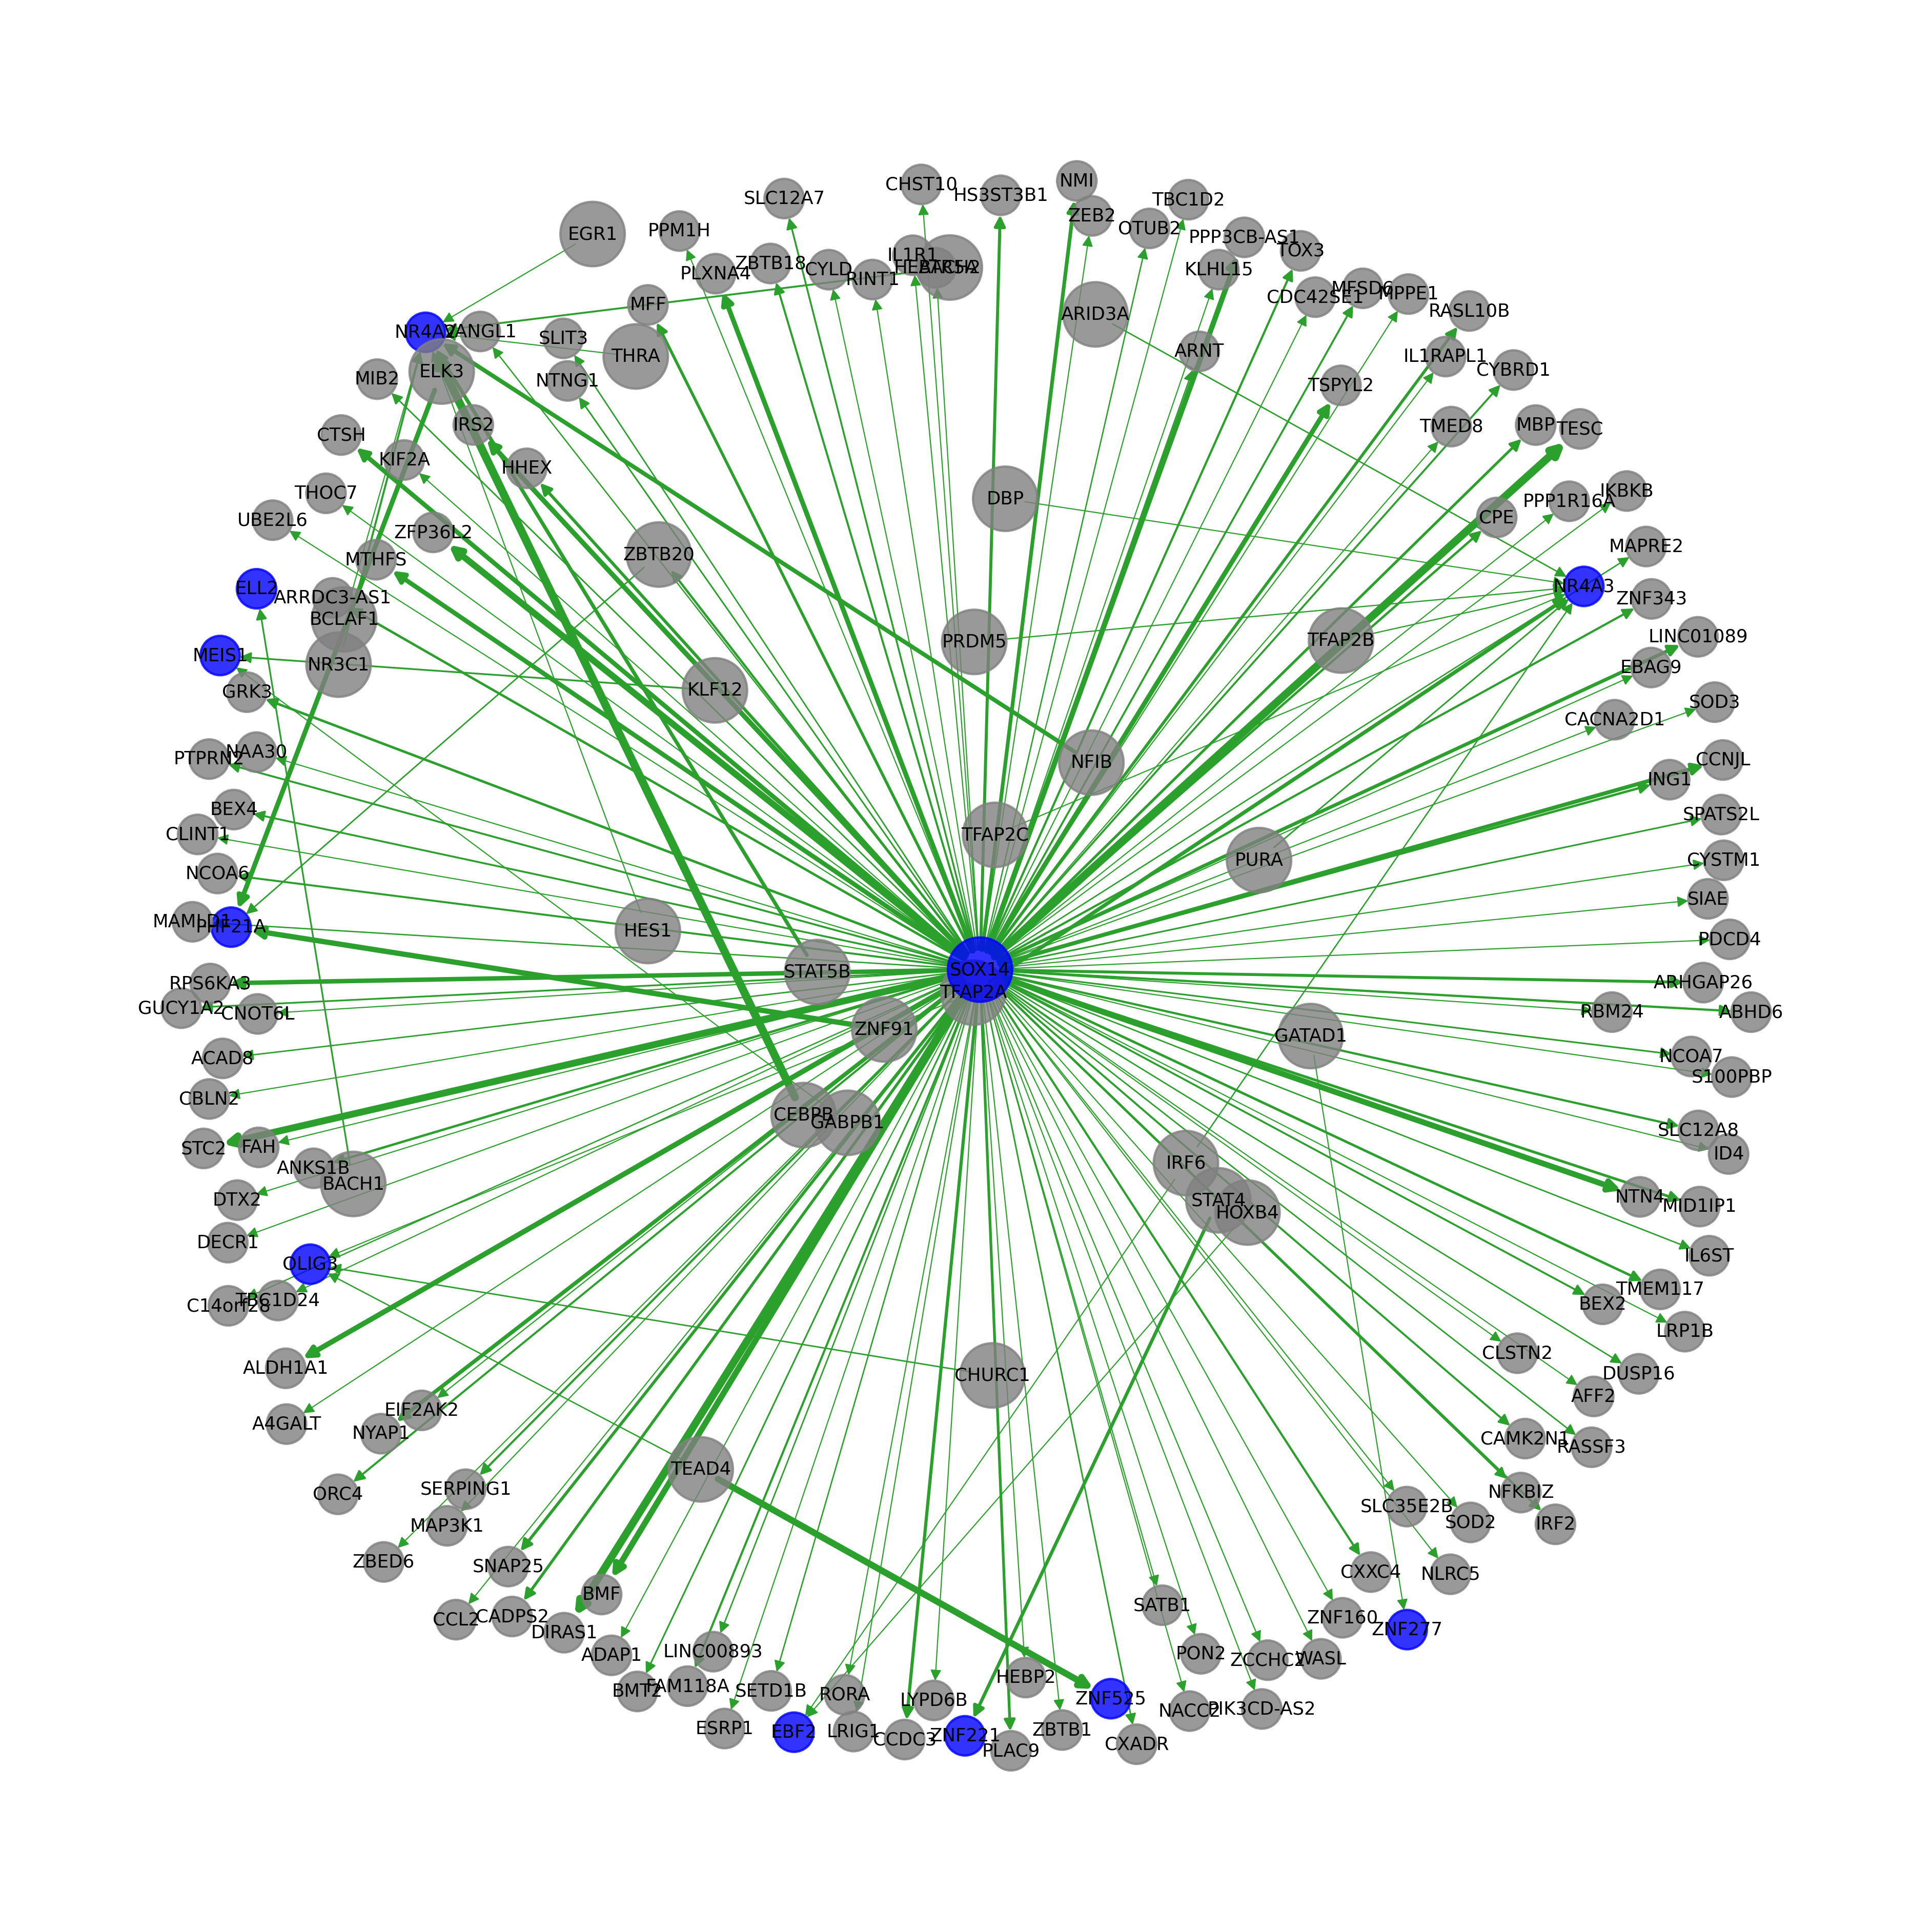

In [144]:
import networkx as nx

# Assume edges_df has columns: TF, Target, Weight

# Build directed graph
G = nx.from_pandas_edgelist(
    edges_df_select,
    source="TF",
    target="Target",
    edge_attr="Weight",
    create_using=nx.DiGraph()
)

# Determine which nodes are TFs
tf_nodes = set(edges_df_select["TF"])
is_tf = {n: n in tf_nodes for n in G.nodes()}

# Node styling
node_sizes = [800 if is_tf[n] else 300 for n in G.nodes()]
# node_colors = ["tab:blue" if is_tf[n] else "tab:gray" for n in G.nodes()] # blue to TF, gray to Target
node_colors = ["blue" if n in genes else "grey" for n in G.nodes()]

# Edge styling: color by sign, width by magnitude
edge_colors = ["tab:red" if d["Weight"] < 0 else "tab:green"
               for _, _, d in G.edges(data=True)]
edge_widths = [max(0.5, abs(d["Weight"]) * 1.5)
               for _, _, d in G.edges(data=True)]

# Layout
pos = nx.spring_layout(G, k=0.5, seed=42)

# Draw
plt.figure(figsize=(12, 12))
nx.draw_networkx_nodes(G, pos, node_size=node_sizes,
                       node_color=node_colors, alpha=0.8)
nx.draw_networkx_edges(G, pos, edge_color=edge_colors, width=edge_widths,
                       arrows=True, arrowsize=10)
nx.draw_networkx_labels(G, pos, font_size=8)

plt.axis("off")
plt.tight_layout()
plt.show()

In [145]:
tf_weight = pd.DataFrame(index = tf_in_data, columns = ['n_TF','n_Target','weights'])
for tf in tf_in_data:
    a = edges_df['TF']==tf
    b = edges_df['Target']==tf
    tf_weight.loc[tf, 'n_TF'] = sum(a)
    tf_weight.loc[tf, 'n_Target'] = sum(b)
    tf_weight.loc[tf, 'weights'] = np.sum(edges_df.loc[a|b, 'Weight'])

In [146]:
tf_weight = tf_weight.sort_values(by="weights", ascending=False)

In [147]:
tf_weight['TF'] = tf_weight.index
tf_weight.index = range(1403)

ValueError: Length mismatch: Expected axis has 1407 elements, new values have 1403 elements

In [ ]:
row_numbers = tf_weight.index[tf_weight['TF'].isin(genes)].tolist()
print(row_numbers)